
# DS-A4: Model Comparison and Calibration Lab

## 1. Problem Statement

This study aims to evaluate and compare machine-learning classification models using in-situ geochemical data from phosphatic components of the Early Cambrian Abbottabad Formation, Kakul-Garlaniyan, Pakistan.

The study uses EPMA major-element compositions and LA-ICP-MS trace-element geochemical data to investigate whether different phosphatic components can be distinguished using their geochemical characteristics.

## 2. Research Question

Can machine-learning models distinguish oolite cores, oolite rims, pellet cores, and pellet rims using their in-situ geochemical compositions, and how reliable are their predicted probabilities?

## 3. Study Objective

The objective is to compare simple and complex classification models under an identical evaluation protocol, assess their predictive and probability-calibration performance, analyze classification errors, and determine an appropriate classification threshold based on error costs and human review capacity.

## 4. Dataset

The analysis will use Supplementary File 2 from the published Journal of Asian Earth Sciences study. The dataset contains in-situ EPMA and LA-ICP-MS measurements of phosphatic components.

The mineral phase will be investigated as the candidate target variable.


In [ ]:

# 1. Import required libraries

import pandas as pd
import numpy as np

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully.
Pandas version: 3.1.1
NumPy version: 2.5.4


In [2]:

# 2. Define the dataset location

file_path = Path(
    r"E:\Asssessment Team\PhD\Data Science\DS_4\data\Supplementray_Files.xlsx"
)

# Check whether the file exists

if file_path.exists():
    print("Dataset found successfully!")
    print("File:", file_path.name)
    print("File size:", round(file_path.stat().st_size / 1024, 2), "KB")
else:
    raise FileNotFoundError(
        "Supplementary Excel file was not found. Check the file path."
    )


Dataset found successfully!
File: Supplementray_Files.xlsx
File size: 128.73 KB


In [3]:

# 3. Load Supplementary File 2 only

raw_data = pd.read_excel(
    file_path,
    sheet_name="Supplementary file 2",
    header=2
)

print("Supplementary File 2 loaded successfully!")

print("Number of observations:", raw_data.shape[0])
print("Number of columns:", raw_data.shape[1])


Supplementary File 2 loaded successfully!
Number of observations: 103
Number of columns: 75


In [4]:

# 4. Display the first 10 observations

display(raw_data.head(10))


,Unnamed: 0,Points,Mineral phase,F,Na2O,MgO,FeO,P2O5,CaO,MnO,Al2O3,SiO2,Total,Li,Be,B,Sc,V,Ca,Cr,Co,Ni,Cu,Zn,Ga,Ge,As,Se,Rb,Sr,Zr,Nb,Mo,Ag,Cd,In,Sn,Sb,Cs,Ba,Hf,Ta,W,Au,Tl,Bi,Pb,Th,U,La,Ce,Pr,Nd,Sm,Eu,Gd,Tb,Dy,Y,Ho,Er,Tm,Yb,Lu,∑REY,Ce/Ce*,Pr/Pr*,Y/Y*,Eu/Eu*,La/Yb,La/Sm,Y/Ho,87Sr/86Sr Ini,Sr/Ca,Rb/Sr
0,LPL,2-1,Oolite core,4.039,0.287,0.042,0.010,39.977,54.316,0.007,0.136003,0.496413,97.474,4.495539,1.781211,6.050487,0.751170,10.257750,388192.810271,11.139925,0.196778,0.540819,1.234765,7.993858,1.617245,0.781115,3.265495,1.121116,1.059296,1154.983480,6.577110,0.064008,0.187814,0.000000,0.079154,0.000000,0.000397,0.107858,0.076229,199.543504,0.153778,0.005533,0.085979,0.008927,0.027155,0.016466,2.451133,1.005189,28.247229,51.260437,50.891498,13.226631,65.334556,12.735382,3.089331,18.718714,2.560017,18.778042,278.915941,4.588878,13.243609,1.564047,8.912145,1.128986,544.948213,0.391133,1.167234,2.390437,0.906430,0.424606,0.584790,60.780860,0.711625,0.002975,0.000917
1,NaN,2-2,NaN,3.725,0.262,0.028,0.025,40.828,54.754,0.013,0.034185,0.798524,98.560,1.987853,1.100990,3.391203,0.446459,3.631258,391323.166904,1.708331,0.028021,0.402554,0.774975,5.120551,1.350201,0.531312,4.120102,1.738702,0.211350,984.662923,3.132744,0.051540,0.225173,0.019901,0.000000,0.003430,0.126899,0.039542,0.039669,113.526066,0.050290,0.003876,0.106593,0.003164,0.016977,0.013463,2.427896,0.837472,23.359534,53.404014,51.373959,12.992344,61.719437,12.404207,3.293055,19.110671,2.572587,19.499122,258.000488,4.255500,13.377660,1.606674,8.313308,0.978360,522.901385,0.401039,1.193322,2.258834,0.962477,0.474226,0.625510,60.627542,NaN,NaN,NaN
2,NaN,2-3,NaN,3.959,0.306,0.066,0.015,40.352,54.492,0.005,0.031026,0.148559,98.047,3.272041,2.525362,4.954941,0.593160,7.293574,389450.670471,5.532900,0.071200,0.113809,0.790126,8.669151,1.617404,0.973738,3.189984,2.816809,0.265243,894.544240,2.527632,0.018104,0.301992,0.015715,0.000000,0.011240,0.042666,0.120505,0.000000,173.748182,0.054682,0.001197,0.102397,0.000000,0.000000,0.006136,1.753225,1.379267,29.895780,69.144898,65.882511,16.661532,74.982110,15.240629,3.829297,22.934031,3.114236,24.416176,330.008920,5.656887,17.536755,1.998253,9.973477,1.381669,662.761382,0.411578,1.241588,2.237458,0.924847,0.511799,0.659154,58.337554,NaN,NaN,NaN
3,NaN,5-1,NaN,3.976,0.211,0.096,0.021,41.057,54.716,0.000,0.105539,1.471582,98.957,3.251387,1.491991,7.558724,0.578535,9.712137,391051.583452,15.054818,0.071104,0.169200,1.231533,4.401766,1.453536,1.058669,3.518025,1.528631,0.943659,1091.214559,6.594636,0.090181,0.299828,0.022757,0.311476,0.013492,0.077779,0.030523,0.018909,283.991039,0.096025,0.001278,0.086544,0.000000,0.002632,0.024258,1.840303,1.231757,25.415525,57.419136,53.659086,13.621282,63.129541,14.064289,3.190684,19.791429,2.703266,20.189824,269.548655,4.701868,13.666707,1.622296,8.898514,1.201576,547.408153,0.400618,1.216411,2.204148,0.871332,0.476349,0.593155,57.327998,0.711681,0.002790,0.000865
4,NaN,5-2,NaN,4.078,0.306,0.063,0.029,40.236,54.642,0.012,0.129656,0.384135,98.194,4.342306,3.166016,6.292931,0.360237,14.899902,390522.710414,14.199617,0.000000,0.118146,1.128739,8.336341,1.211591,0.601210,2.663321,1.835701,1.011092,996.299749,3.318590,0.083208,0.600033,0.000000,0.253687,0.001065,0.000000,0.000000,0.025603,277.072984,0.082375,0.005825,0.064505,0.000000,0.059419,0.009257,2.260954,1.282709,26.475735,52.497414,50.602265,12.865344,61.356703,14.211247,3.183749,19.272370,2.677980,19.572317,281.993722,4.445943,13.854974,1.592477,9.030058,1.218639,548.375201,0.399287,1.191512,2.409710,0.880463,0.429174,0.536705,63.427197,NaN,NaN,NaN
5,NaN,5-3,NaN,4.042,0.202,0.051,0.014,40.418,54.532,0.003,0.026918,0.341804,98.014,4.159746,1.804047,5.829671,0.563635,3.486123,389736.547789,1.959337,0.120013,0.033693,1.540896,6.459337,1.264953,1.110391,2.435068,3.383274,0.152614,1145.616275,3.845851,0.042242,0.530115,0.014581,0.000000,0.000000,0.284840,0.000000,0.000000,334.126707,0.069449,0.004260,0.052186,0.000000,0.000000,0.000000,1.748915,1.601665,24

In [5]:

# 5. Examine all column names

print("Total number of columns:", len(raw_data.columns))

for number, column in enumerate(raw_data.columns, start=1):
    print(number, ":", column)


Total number of columns: 75
1 : Unnamed: 0
2 : Points
3 : Mineral phase 
4 : F
5 : Na2O 
6 : MgO
7 : FeO
8 : P2O5
9 : CaO
10 : MnO
11 : Al2O3
12 : SiO2
13 : Total
14 : Li
15 : Be
16 : B
17 : Sc
18 : V
19 : Ca
20 : Cr
21 : Co
22 : Ni
23 : Cu
24 : Zn
25 : Ga
26 : Ge
27 : As
28 : Se
29 : Rb
30 : Sr
31 : Zr
32 : Nb
33 : Mo
34 : Ag
35 : Cd
36 : In
37 : Sn
38 : Sb
39 : Cs
40 : Ba
41 : Hf
42 : Ta
43 : W
44 : Au
45 : Tl
46 : Bi
47 : Pb
48 : Th
49 : U
50 : La
51 : Ce
52 : Pr
53 : Nd
54 : Sm
55 : Eu
56 : Gd
57 : Tb
58 : Dy
59 : Y
60 : Ho
61 : Er
62 : Tm
63 : Yb
64 : Lu
65 : ∑REY
66 : Ce/Ce* 
67 : Pr/Pr* 
68 : Y/Y*
69 : Eu/Eu*
70 : La/Yb
71 : La/Sm
72 : Y/Ho
73 : 87Sr/86Sr Ini
74 : Sr/Ca
75 : Rb/Sr


In [6]:

# 6. Create a working copy for label inspection

data = raw_data.copy()

# Rename the first three columns for clarity

data = data.rename(columns={
    "Unnamed: 0": "Stratigraphic_unit",
    "Points": "Point_ID",
    "Mineral phase ": "Mineral_phase"
})

# Fill down the merged-cell labels in the working copy

data["Stratigraphic_unit"] = data["Stratigraphic_unit"].ffill()

data["Mineral_phase"] = (
    data["Mineral_phase"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .ffill()
)

# Display label distribution

print("Mineral-phase distribution:")

display(
    data["Mineral_phase"]
    .value_counts()
    .to_frame("Number_of_observations")
)

print("\nStratigraphic distribution:")

display(
    data.groupby(
        ["Stratigraphic_unit", "Mineral_phase"],
        observed=True
    ).size().to_frame("Observations")
)


Mineral-phase distribution:


,Number_of_observations
Mineral_phase,
Oolite core,35
Oolite Rim,27
Pellet Rim,21
Pellet Core,20



Stratigraphic distribution:


Observations
Stratigraphic_unit Mineral_phase              
LPL                Oolite Rim                6
                   Oolite core               8
                   Pellet Core               3
                   Pellet Rim                4
MPL                Oolite Rim                7
                   Oolite core              10
                   Pellet Core               8
                   Pellet Rim                8
UPL                Oolite Rim               14
                   Oolite core              17
                   Pellet Core               9
                   Pellet Rim                9

In [7]:

# 7. Dataset structure and data types

print("Dataset dimensions:", data.shape)

print("\nColumn names and data types:")

display(
    pd.DataFrame({
        "Column": data.columns,
        "Data_Type": data.dtypes.astype(str).values
    })
)

print("\nFirst 10 analytical point identifiers:")

display(
    data[[
        "Stratigraphic_unit",
        "Point_ID",
        "Mineral_phase"
    ]].head(10)
)


Dataset dimensions: (103, 75)

Column names and data types:


,Column,Data_Type
0,Stratigraphic_unit,str
1,Point_ID,str
2,Mineral_phase,string
3,F,float64
4,Na2O,float64
5,MgO,float64
6,FeO,float64
7,P2O5,float64
8,CaO,float64
9,MnO,float64



First 10 analytical point identifiers:


,Stratigraphic_unit,Point_ID,Mineral_phase
0,LPL,2-1,Oolite core
1,LPL,2-2,Oolite core
2,LPL,2-3,Oolite core
3,LPL,5-1,Oolite core
4,LPL,5-2,Oolite core
5,LPL,5-3,Oolite core
6,LPL,6-1,Oolite core
7,LPL,6-2,Oolite core
8,LPL,4-1,Oolite Rim
9,LPL,4-2,Oolite Rim


In [8]:

# 8. Missing value analysis

missing_summary = pd.DataFrame({
    "Missing_Count": data.isna().sum(),
    "Missing_Percentage": (
        data.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary)



,Missing_Count,Missing_Percentage
87Sr/86Sr Ini,76,73.79
Rb/Sr,76,73.79
Sr/Ca,76,73.79
F,0,0.00
Na2O,0,0.00
MgO,0,0.00
FeO,0,0.00
P2O5,0,0.00
Stratigraphic_unit,0,0.00
Point_ID,0,0.00


In [9]:

# 9. Examine analytical point identifiers

print("Total observations:", len(data))

print(
    "Duplicate point identifiers within stratigraphic units:",
    data.duplicated(
        subset=["Stratigraphic_unit", "Point_ID"]
    ).sum()
)

print("\nObservations by stratigraphic unit:")

display(
    data.groupby("Stratigraphic_unit").size()
)

print("\nObservations by mineral phase:")

display(
    data.groupby("Mineral_phase").size()
)


Total observations: 103
Duplicate point identifiers within stratigraphic units: 41

Observations by stratigraphic unit:


Stratigraphic_unit
LPL    21
MPL    33
UPL    49
dtype: int64


Observations by mineral phase:


Mineral_phase
Oolite Rim     27
Oolite core    35
Pellet Core    20
Pellet Rim     21
dtype: int64


## 5. Frozen Evaluation Protocol

### 5.1 Classification Task

The task is a four-class classification problem using in-situ geochemical measurements of phosphatic components.

The target variable is Mineral_phase, consisting of:
- Oolite core
- Oolite Rim
- Pellet Core
- Pellet Rim

### 5.2 Data Splitting Strategy

Stratified Group 5-Fold Cross-Validation will be used.

- Number of folds: 5
- Random seed: 42
- Grouping variable: Stratigraphic unit combined with Point ID.
- The same folds will be used for all three models.

This grouping strategy is intended to prevent linked analytical points from appearing in both training and testing partitions.

### 5.3 Model Comparison

Three classification models will be evaluated:
1. Logistic Regression
2. Random Forest
3. Support Vector Machine

All models will use the same evaluation folds and performance metrics.

### 5.4 Evaluation Metrics

The evaluation will include:
- Precision-Recall curves
- ROC curves
- Brier score
- Expected Calibration Error (ECE)
- Calibration curves
- Uncertainty intervals
- Classification error analysis

### 5.5 Reproducibility

The random seed, data version, model configurations, evaluation folds and software dependencies will be documented and retained.


In [10]:


# 10. Load the existing frozen evaluation folds

from pathlib import Path
import pandas as pd

fold_file = Path(
    r"E:\Asssessment Team\PhD\Data Science\DS_4\results\frozen_fold_assignments.csv"
)

saved_folds = pd.read_csv(fold_file)

assert len(saved_folds) == len(data)

for col in ["Stratigraphic_unit", "Point_ID", "Mineral_phase"]:
    assert (
        data[col].astype(str).str.strip().tolist()
        == saved_folds[col].astype(str).str.strip().tolist()
    ), f"Mismatch in {col}"

data["Group_ID"] = saved_folds["Group_ID"].to_numpy()
data["Fold"] = saved_folds["Fold"].astype(int).to_numpy()

print("Frozen evaluation folds loaded successfully.")
print("Observations:", len(data))
print("Number of folds:", data["Fold"].nunique())


Frozen evaluation folds loaded successfully.
Observations: 103
Number of folds: 5


In [11]:

# 11. Verify group separation

for fold in range(1, 6):

    train_groups = set(
        data.loc[data["Fold"] != fold, "Group_ID"]
    )

    test_groups = set(
        data.loc[data["Fold"] == fold, "Group_ID"]
    )

    overlap = train_groups.intersection(test_groups)

    print(
        f"Fold {fold}: "
        f"Overlapping groups = {len(overlap)}"
    )

    assert len(overlap) == 0

print("\nAll five folds passed the group-separation check.")


Fold 1: Overlapping groups = 0
Fold 2: Overlapping groups = 0
Fold 3: Overlapping groups = 0
Fold 4: Overlapping groups = 0
Fold 5: Overlapping groups = 0

All five folds passed the group-separation check.


In [12]:


# 12. Verify frozen assignments without overwriting the CSV

columns = [
    "Stratigraphic_unit",
    "Point_ID",
    "Mineral_phase",
    "Group_ID",
    "Fold"
]

pd.testing.assert_frame_equal(
    data[columns].astype(str).reset_index(drop=True),
    saved_folds[columns].astype(str).reset_index(drop=True)
)

print("Frozen assignments verified; CSV unchanged.")


Frozen assignments verified; CSV unchanged.


In [13]:

# 13. Standardize column names

data.columns = data.columns.astype(str).str.strip()

# Define metadata columns
metadata_columns = [
    "Stratigraphic_unit",
    "Point_ID",
    "Mineral_phase",
    "Group_ID",
    "Fold"
]

# Display all available variables
print("Available dataset columns:")

for i, col in enumerate(data.columns, start=1):
    print(i, ":", col)


Available dataset columns:
1 : Stratigraphic_unit
2 : Point_ID
3 : Mineral_phase
4 : F
5 : Na2O
6 : MgO
7 : FeO
8 : P2O5
9 : CaO
10 : MnO
11 : Al2O3
12 : SiO2
13 : Total
14 : Li
15 : Be
16 : B
17 : Sc
18 : V
19 : Ca
20 : Cr
21 : Co
22 : Ni
23 : Cu
24 : Zn
25 : Ga
26 : Ge
27 : As
28 : Se
29 : Rb
30 : Sr
31 : Zr
32 : Nb
33 : Mo
34 : Ag
35 : Cd
36 : In
37 : Sn
38 : Sb
39 : Cs
40 : Ba
41 : Hf
42 : Ta
43 : W
44 : Au
45 : Tl
46 : Bi
47 : Pb
48 : Th
49 : U
50 : La
51 : Ce
52 : Pr
53 : Nd
54 : Sm
55 : Eu
56 : Gd
57 : Tb
58 : Dy
59 : Y
60 : Ho
61 : Er
62 : Tm
63 : Yb
64 : Lu
65 : ∑REY
66 : Ce/Ce*
67 : Pr/Pr*
68 : Y/Y*
69 : Eu/Eu*
70 : La/Yb
71 : La/Sm
72 : Y/Ho
73 : 87Sr/86Sr Ini
74 : Sr/Ca
75 : Rb/Sr
76 : Group_ID
77 : Fold


In [14]:

# 14. Missing-value assessment

geochemical_data = data.drop(
    columns=metadata_columns,
    errors="ignore"
).apply(pd.to_numeric, errors="coerce")

missing_report = pd.DataFrame({
    "Missing_Count": geochemical_data.isna().sum(),
    "Missing_Percentage": (
        geochemical_data.isna().mean() * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)


,Missing_Count,Missing_Percentage
Rb/Sr,76,73.79
87Sr/86Sr Ini,76,73.79
Sr/Ca,76,73.79
F,0,0.00
P2O5,0,0.00
Na2O,0,0.00
MgO,0,0.00
FeO,0,0.00
Al2O3,0,0.00
MnO,0,0.00


In [15]:

# 15. Define candidate geochemical predictors

epma_features = [
    "F", "Na2O", "MgO", "FeO", "P2O5",
    "CaO", "MnO", "Al2O3", "SiO2"
]

# LA-ICP-MS elemental variables
la_icpms_features = [
    col for col in geochemical_data.columns
    if col in [
        "Li", "Be", "B", "Sc", "V", "Ca", "Cr",
        "Co", "Ni", "Cu", "Zn", "Ga", "Ge", "As",
        "Se", "Rb", "Sr", "Zr", "Nb", "Mo", "Ag",
        "Cd", "In", "Sn", "Sb", "Cs", "Ba", "Hf",
        "Ta", "W", "Au", "Tl", "Bi", "Pb", "Th",
        "U", "La", "Ce", "Pr", "Nd", "Sm", "Eu",
        "Gd", "Tb", "Dy", "Y", "Ho", "Er", "Tm",
        "Yb", "Lu"
    ]
]

candidate_features = (
    epma_features + la_icpms_features
)

print("Number of EPMA predictors:", len(epma_features))
print("Number of LA-ICP-MS predictors:", len(la_icpms_features))
print("Total candidate predictors:", len(candidate_features))

display(
    pd.DataFrame({
        "Predictor": candidate_features,
        "Data_Type": (
            ["EPMA"] * len(epma_features)
            + ["LA-ICP-MS"] * len(la_icpms_features)
        )
    })
)


Number of EPMA predictors: 9
Number of LA-ICP-MS predictors: 51
Total candidate predictors: 60


,Predictor,Data_Type
0,F,EPMA
1,Na2O,EPMA
2,MgO,EPMA
3,FeO,EPMA
4,P2O5,EPMA
5,CaO,EPMA
6,MnO,EPMA
7,Al2O3,EPMA
8,SiO2,EPMA
9,Li,LA-ICP-MS


In [16]:

# 16. Examine candidate predictor availability

X_candidate = data[candidate_features].apply(
    pd.to_numeric,
    errors="coerce"
)

y = data["Mineral_phase"]

print("Candidate predictor dimensions:", X_candidate.shape)

print("\nMissing values:", X_candidate.isna().sum().sum())

print("\nTarget distribution:")
display(y.value_counts().to_frame("Observations"))

print("\nPredictor summary statistics:")
display(X_candidate.describe().T)


Candidate predictor dimensions: (103, 60)

Missing values: 0

Target distribution:


,Observations
Mineral_phase,
Oolite core,35
Oolite Rim,27
Pellet Rim,21
Pellet Core,20



Predictor summary statistics:


,count,mean,std,min,25%,50%,75%,max
F,103.0,3.802767,0.372268,2.471000,3.692500,3.816000,3.993000,4.708000
Na2O,103.0,0.225107,0.079634,0.000000,0.186000,0.227000,0.283000,0.413000
MgO,103.0,0.072913,0.026591,0.001000,0.059000,0.073000,0.090000,0.132000
FeO,103.0,0.020786,0.018746,0.000000,0.008000,0.017000,0.028000,0.127000
P2O5,103.0,40.072388,0.591678,38.569000,39.678000,40.136000,40.484000,41.669000
CaO,103.0,54.305670,0.466699,52.559000,54.105000,54.407000,54.588000,55.187000
MnO,103.0,0.008291,0.010303,0.000000,0.000000,0.006000,0.012500,0.058000
Al2O3,103.0,0.065265,0.093480,0.002165,0.017383,0.035102,0.067738,0.679992
SiO2,103.0,0.418753,0.533909,0.057744,0.152875,0.234161,0.487021,3.968171
Li,103.0,3.993219,1.637826,0.805974,2.871973,3.954781,4.923241,7.894605


In [17]:

# 17. Define candidate geochemical predictor variables

# EPMA major-element measurements
epma_features = [
    "F", "Na2O", "MgO", "FeO", "P2O5",
    "CaO", "MnO", "Al2O3", "SiO2"
]

# LA-ICP-MS elemental measurements
la_icpms_features = [
    "Li", "Be", "B", "Sc", "V", "Ca", "Cr",
    "Co", "Ni", "Cu", "Zn", "Ga", "Ge", "As",
    "Se", "Rb", "Sr", "Zr", "Nb", "Mo", "Ag",
    "Cd", "In", "Sn", "Sb", "Cs", "Ba", "Hf",
    "Ta", "W", "Au", "Tl", "Bi", "Pb", "Th",
    "U", "La", "Ce", "Pr", "Nd", "Sm", "Eu",
    "Gd", "Tb", "Dy", "Y", "Ho", "Er", "Tm",
    "Yb", "Lu"
]

candidate_features = epma_features + la_icpms_features

# Verify that all requested columns exist
missing_columns = [
    col for col in candidate_features
    if col not in data.columns
]

print("EPMA variables:", len(epma_features))
print("LA-ICP-MS variables:", len(la_icpms_features))
print("Total candidate predictors:", len(candidate_features))
print("Unavailable columns:", missing_columns)


EPMA variables: 9
LA-ICP-MS variables: 51
Total candidate predictors: 60
Unavailable columns: []


In [18]:

# 18. Examine candidate predictor quality

X_candidate = data[candidate_features].apply(
    pd.to_numeric,
    errors="coerce"
)

feature_quality = pd.DataFrame({
    "Missing_values": X_candidate.isna().sum(),
    "Missing_percentage": (
        X_candidate.isna().mean() * 100
    ).round(2),
    "Unique_values": X_candidate.nunique(),
    "Standard_deviation": X_candidate.std()
})

display(feature_quality)

print("Total candidate features:", X_candidate.shape[1])
print("Total observations:", X_candidate.shape[0])
print("Total missing measurements:", X_candidate.isna().sum().sum())


,Missing_values,Missing_percentage,Unique_values,Standard_deviation
F,0,0.0,98,0.372268
Na2O,0,0.0,87,0.079634
MgO,0,0.0,62,0.026591
FeO,0,0.0,42,0.018746
P2O5,0,0.0,103,0.591678
CaO,0,0.0,98,0.466699
MnO,0,0.0,25,0.010303
Al2O3,0,0.0,103,0.093480
SiO2,0,0.0,99,0.533909
Li,0,0.0,103,1.637826


Total candidate features: 60
Total observations: 103
Total missing measurements: 0


In [19]:

# 19. Examine repeated analytical identifiers

identifier_check = (
    data.groupby(
        ["Stratigraphic_unit", "Point_ID"]
    )
    .agg(
        Number_of_observations=("Mineral_phase", "size"),
        Number_of_phases=("Mineral_phase", "nunique"),
        Mineral_phases=(
            "Mineral_phase",
            lambda x: ", ".join(sorted(x.unique()))
        )
    )
    .reset_index()
)

repeated_identifiers = identifier_check[
    identifier_check["Number_of_observations"] > 1
]

print("Total unique identifier groups:", len(identifier_check))
print("Repeated identifier groups:", len(repeated_identifiers))

display(repeated_identifiers)


Total unique identifier groups: 62
Repeated identifier groups: 32


,Stratigraphic_unit,Point_ID,Number_of_observations,Number_of_phases,Mineral_phases
3,LPL,4-1,2,2,"Oolite Rim, Pellet Core"
4,LPL,4-2,2,2,"Oolite Rim, Pellet Core"
5,LPL,5-1,2,2,"Oolite core, Pellet Core"
8,LPL,6-1,2,2,"Oolite core, Pellet Rim"
9,LPL,6-2,2,2,"Oolite core, Pellet Rim"
20,MPL,13-1,2,2,"Oolite Rim, Pellet Core"
21,MPL,13-2,2,2,"Oolite Rim, Pellet Core"
22,MPL,14-1,2,2,"Oolite core, Pellet Core"
23,MPL,14-2,2,2,"Oolite core, Pellet Core"
24,MPL,15-1,2,2,"Oolite core, Pellet Core"


In [20]:

# 20. Check class distribution across five folds

fold_distribution = pd.crosstab(
    data["Fold"],
    data["Mineral_phase"]
)

print("Mineral-phase distribution across folds:")
display(fold_distribution)

print("\nTotal observations in each fold:")
display(data["Fold"].value_counts().sort_index())


Mineral-phase distribution across folds:


Mineral_phase,Oolite Rim,Oolite core,Pellet Core,Pellet Rim
Fold,,,,
1,5,7,4,4
2,6,7,4,4
3,5,7,4,4
4,4,7,4,5
5,7,7,4,4



Total observations in each fold:


Fold
1    20
2    21
3    20
4    20
5    22
Name: count, dtype: int64

In [21]:

# 21. Verify group separation across folds

for fold in sorted(data["Fold"].unique()):

    train_groups = set(
        data.loc[data["Fold"] != fold, "Group_ID"]
    )

    test_groups = set(
        data.loc[data["Fold"] == fold, "Group_ID"]
    )

    overlap = train_groups.intersection(test_groups)

    print(f"Fold {fold}: {len(overlap)} overlapping groups")

    assert len(overlap) == 0

print("\nGroup separation verification completed.")


Fold 1: 0 overlapping groups
Fold 2: 0 overlapping groups
Fold 3: 0 overlapping groups
Fold 4: 0 overlapping groups
Fold 5: 0 overlapping groups

Group separation verification completed.


In [22]:


# 12. Verify frozen assignments without overwriting the CSV

columns = [
    "Stratigraphic_unit",
    "Point_ID",
    "Mineral_phase",
    "Group_ID",
    "Fold"
]

pd.testing.assert_frame_equal(
    data[columns].astype(str).reset_index(drop=True),
    saved_folds[columns].astype(str).reset_index(drop=True)
)

print("Frozen assignments verified; CSV unchanged.")



Frozen assignments verified; CSV unchanged.


In [23]:
display(pd.crosstab(data["Fold"], data["Mineral_phase"]))

Mineral_phase,Oolite Rim,Oolite core,Pellet Core,Pellet Rim
Fold,,,,
1,5,7,4,4
2,6,7,4,4
3,5,7,4,4
4,4,7,4,5
5,7,7,4,4


In [24]:
for fold in sorted(data["Fold"].unique()):

    train_groups = set(
        data.loc[data["Fold"] != fold, "Group_ID"]
    )

    test_groups = set(
        data.loc[data["Fold"] == fold, "Group_ID"]
    )

    overlap = train_groups.intersection(test_groups)

    print(f"Fold {fold}: {len(overlap)} overlapping groups")

    assert len(overlap) == 0

print("All folds passed group-separation checks.")

Fold 1: 0 overlapping groups
Fold 2: 0 overlapping groups
Fold 3: 0 overlapping groups
Fold 4: 0 overlapping groups
Fold 5: 0 overlapping groups
All folds passed group-separation checks.


In [25]:

import sys
import pandas as pd
import sklearn

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)


Python version: 3.13.9
Python executable: e:\Asssessment Team\PhD\Data Science\DS_4\.venv\Scripts\python.exe
Pandas version: 3.1.1
Scikit-learn version: 1.9.1


In [26]:

# 23. Verify project paths and frozen evaluation data

from pathlib import Path
import pandas as pd

project_dir = Path(
    r"E:\Asssessment Team\PhD\Data Science\DS_4"
)

data_file = project_dir / "data" / "Supplementray_Files.xlsx"
fold_file = project_dir / "results" / "frozen_fold_assignments.csv"

print("Dataset exists:", data_file.exists())
print("Frozen folds exist:", fold_file.exists())

assert data_file.exists(), "Supplementary dataset not found."
assert fold_file.exists(), "Frozen fold assignments not found."

saved_folds = pd.read_csv(fold_file)

print("\nSaved observations:", len(saved_folds))
print("Number of folds:", saved_folds["Fold"].nunique())
print("\nSaved fold distribution:")

display(
    pd.crosstab(
        saved_folds["Fold"],
        saved_folds["Mineral_phase"]
    )
)


Dataset exists: True
Frozen folds exist: True

Saved observations: 103
Number of folds: 5

Saved fold distribution:


Mineral_phase,Oolite Rim,Oolite core,Pellet Core,Pellet Rim
Fold,,,,
1,5,7,4,4
2,6,7,4,4
3,5,7,4,4
4,4,7,4,5
5,7,7,4,4


In [27]:

# 24. Load geochemical measurements and restore frozen folds

raw_data = pd.read_excel(
    data_file,
    sheet_name="Supplementary file 2",
    header=2
)

data = raw_data.copy()

# Standardize column names
data.columns = data.columns.astype(str).str.strip()

data = data.rename(columns={
    "Unnamed: 0": "Stratigraphic_unit",
    "Points": "Point_ID",
    "Mineral phase": "Mineral_phase"
})

# Restore labels from merged Excel cells
data["Stratigraphic_unit"] = (
    data["Stratigraphic_unit"].ffill()
)

data["Mineral_phase"] = (
    data["Mineral_phase"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .ffill()
)

# Check row alignment before restoring assignments
assert len(data) == len(saved_folds)

for col in [
    "Stratigraphic_unit",
    "Point_ID",
    "Mineral_phase"
]:
    original = data[col].astype("string").str.strip()
    frozen = saved_folds[col].astype("string").str.strip()

    assert original.reset_index(drop=True).equals(
        frozen.reset_index(drop=True)
    ), f"Mismatch found in {col}"

# Restore existing assignments — do not regenerate
data["Group_ID"] = saved_folds["Group_ID"].to_numpy()
data["Fold"] = saved_folds["Fold"].to_numpy()

# Verify groups are not split across folds
assert (
    data.groupby("Group_ID")["Fold"].nunique() == 1
).all(), "Group leakage detected in saved folds"

print("Original geochemical data loaded successfully.")
print("Frozen assignments restored successfully.")
print("Observations:", len(data))
print("Total columns:", data.shape[1])
print("Evaluation folds:", data["Fold"].nunique())
print("Group separation verified.")


Original geochemical data loaded successfully.
Frozen assignments restored successfully.
Observations: 103
Total columns: 77
Evaluation folds: 5
Group separation verified.


In [28]:

# 25. Prepare and inspect candidate geochemical predictors

import numpy as np
import pandas as pd

# EPMA major-element measurements
epma_features = [
    "F", "Na2O", "MgO", "FeO", "P2O5",
    "CaO", "MnO", "Al2O3", "SiO2"
]

# LA-ICP-MS trace-element measurements
la_icpms_features = [
    "Li", "Be", "B", "Sc", "V", "Ca", "Cr",
    "Co", "Ni", "Cu", "Zn", "Ga", "Ge", "As",
    "Se", "Rb", "Sr", "Zr", "Nb", "Mo", "Ag",
    "Cd", "In", "Sn", "Sb", "Cs", "Ba", "Hf",
    "Ta", "W", "Au", "Tl", "Bi", "Pb", "Th",
    "U", "La", "Ce", "Pr", "Nd", "Sm", "Eu",
    "Gd", "Tb", "Dy", "Y", "Ho", "Er", "Tm",
    "Yb", "Lu"
]

candidate_features = epma_features + la_icpms_features

# Verify all predictors are available
missing_features = [
    col for col in candidate_features
    if col not in data.columns
]

assert not missing_features, (
    f"Unavailable predictors: {missing_features}"
)

assert len(candidate_features) == len(set(candidate_features)), (
    "Duplicate predictor names detected."
)

# Create feature matrix and target
X = data[candidate_features].apply(
    pd.to_numeric, errors="coerce"
).replace([np.inf, -np.inf], np.nan)

y = data["Mineral_phase"]

print("Observations:", X.shape[0])
print("Candidate predictors:", X.shape[1])
print("Target classes:", y.nunique())
print("Missing measurements:", X.isna().sum().sum())

# Assess predictor quality
feature_quality = pd.DataFrame({
    "Missing_Count": X.isna().sum(),
    "Missing_Percentage": (
        X.isna().mean() * 100
    ).round(2),
    "Unique_Values": X.nunique(dropna=True)
})

print("\nPredictors with 100% missing values:")
print(
    feature_quality.index[
        feature_quality["Missing_Percentage"] == 100
    ].tolist()
)

print("\nPredictors with one or fewer unique values:")
print(
    feature_quality.index[
        feature_quality["Unique_Values"] <= 1
    ].tolist()
)

print("\nTop 15 predictors by missing values:")
display(
    feature_quality.sort_values(
        "Missing_Percentage",
        ascending=False
    ).head(15)
)


Observations: 103
Candidate predictors: 60
Target classes: 4
Missing measurements: 0

Predictors with 100% missing values:
[]

Predictors with one or fewer unique values:
[]

Top 15 predictors by missing values:


,Missing_Count,Missing_Percentage,Unique_Values
F,0,0.0,98
Na2O,0,0.0,87
MgO,0,0.0,62
FeO,0,0.0,42
P2O5,0,0.0,103
CaO,0,0.0,98
MnO,0,0.0,25
Al2O3,0,0.0,103
SiO2,0,0.0,99
Li,0,0.0,103


In [29]:

# 26. Logistic Regression baseline using frozen folds

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    log_loss
)

# Verify modeling inputs
assert len(X) == len(y) == len(data)
assert X.shape[1] > 0
assert not X.isna().all().any(), (
    "Some predictors contain only missing values."
)
assert not y.isna().any()
assert data["Fold"].nunique() == 5

# Store out-of-fold predictions
classes = np.sort(y.unique())
oof_prob = np.zeros((len(y), len(classes)))
oof_pred = np.empty(len(y), dtype=object)

for fold in sorted(data["Fold"].unique()):

    train_idx = np.where(data["Fold"] != fold)[0]
    test_idx = np.where(data["Fold"] == fold)[0]

    # All preprocessing is fitted on training data only
    model = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=1.0,
            max_iter=5000,
            solver="lbfgs"
        ))
    ])

    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    predictions = model.predict(X.iloc[test_idx])
    probabilities = model.predict_proba(X.iloc[test_idx])

    # Align predicted probability columns
    model_classes = model.named_steps[
        "classifier"
    ].classes_

    for j, label in enumerate(model_classes):
        class_idx = np.where(classes == label)[0][0]
        oof_prob[test_idx, class_idx] = probabilities[:, j]

    oof_pred[test_idx] = predictions

    print(f"Fold {fold}: {len(test_idx)} test observations")

# Evaluate all out-of-fold predictions
accuracy = accuracy_score(y, oof_pred)
macro_f1 = f1_score(y, oof_pred, average="macro")
loss = log_loss(y, oof_prob, labels=classes)

print("\nLOGISTIC REGRESSION RESULTS")
print("Accuracy:", round(accuracy, 4))
print("Macro F1:", round(macro_f1, 4))
print("Log loss:", round(loss, 4))

# Save predictions in memory for later comparison
lr_results = pd.DataFrame({
    "Fold": data["Fold"].to_numpy(),
    "Actual": y.to_numpy(),
    "Predicted": oof_pred
})

for j, label in enumerate(classes):
    lr_results[f"Prob_{label}"] = oof_prob[:, j]

display(lr_results.head(10))


Fold 1: 20 test observations
Fold 2: 21 test observations
Fold 3: 20 test observations
Fold 4: 20 test observations
Fold 5: 22 test observations

LOGISTIC REGRESSION RESULTS
Accuracy: 0.3883
Macro F1: 0.3549
Log loss: 3.1934


,Fold,Actual,Predicted,Prob_Oolite Rim,Prob_Oolite core,Prob_Pellet Core,Prob_Pellet Rim
0,4,Oolite core,Oolite core,0.008224,0.789613,0.107173,0.094990
1,2,Oolite core,Pellet Core,0.396013,0.009108,0.490645,0.104234
2,3,Oolite core,Oolite core,0.147582,0.845234,0.001009,0.006175
3,3,Oolite core,Oolite core,0.292580,0.556772,0.076140,0.074509
4,1,Oolite core,Pellet Core,0.002346,0.039494,0.933460,0.024700
5,1,Oolite core,Oolite core,0.398669,0.464407,0.129841,0.007082
6,2,Oolite core,Oolite Rim,0.495307,0.487823,0.011256,0.005614
7,1,Oolite core,Oolite core,0.156978,0.426088,0.017588,0.399345
8,4,Oolite Rim,Oolite core,0.333830,0.652354,0.010094,0.003722
9,2,Oolite Rim,Oolite Rim,0.661962,0.326231,0.011249,0.000559


In [30]:

# 27. Logistic Regression diagnostic evaluation

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)
from pathlib import Path
import numpy as np
import pandas as pd

# Verify prediction probabilities
assert np.isfinite(oof_prob).all()
assert np.allclose(oof_prob.sum(axis=1), 1.0)

print("LOGISTIC REGRESSION: CONFUSION MATRIX")

conf_matrix = confusion_matrix(
    y, oof_pred, labels=classes
)

display(pd.DataFrame(
    conf_matrix,
    index=classes,
    columns=classes
))

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y,
    oof_pred,
    labels=classes,
    zero_division=0
))

# Identify incorrectly classified observations
errors = lr_results[
    lr_results["Actual"] != lr_results["Predicted"]
]

print("Total classification errors:", len(errors))
print("Total correct predictions:", len(y) - len(errors))

# Preserve out-of-fold predictions
results_dir = Path(
    r"E:\Asssessment Team\PhD\Data Science\DS_4\results"
)

results_dir.mkdir(parents=True, exist_ok=True)

output_file = (
    results_dir / "logistic_regression_oof_predictions.csv"
)

lr_results.to_csv(output_file, index=False)

print("\nPredictions saved to:")
print(output_file)


LOGISTIC REGRESSION: CONFUSION MATRIX


,Oolite Rim,Oolite core,Pellet Core,Pellet Rim
Oolite Rim,18,6,1,2
Oolite core,13,14,2,6
Pellet Core,3,3,4,10
Pellet Rim,2,4,11,4



CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Oolite Rim       0.50      0.67      0.57        27
 Oolite core       0.52      0.40      0.45        35
 Pellet Core       0.22      0.20      0.21        20
  Pellet Rim       0.18      0.19      0.19        21

    accuracy                           0.39       103
   macro avg       0.36      0.36      0.35       103
weighted avg       0.39      0.39      0.38       103

Total classification errors: 63
Total correct predictions: 40

Predictions saved to:
E:\Asssessment Team\PhD\Data Science\DS_4\results\logistic_regression_oof_predictions.csv


In [31]:

# 28. Random Forest classification using frozen folds

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, log_loss

import numpy as np
import pandas as pd

# Store out-of-fold predictions
rf_prob = np.zeros((len(y), len(classes)))
rf_pred = np.empty(len(y), dtype=object)

for fold in sorted(data["Fold"].unique()):

    train_idx = np.where(data["Fold"] != fold)[0]
    test_idx = np.where(data["Fold"] == fold)[0]

    model = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    predictions = model.predict(X.iloc[test_idx])
    probabilities = model.predict_proba(X.iloc[test_idx])

    model_classes = model.named_steps[
        "classifier"
    ].classes_

    for j, label in enumerate(model_classes):
        class_idx = np.where(classes == label)[0][0]
        rf_prob[test_idx, class_idx] = probabilities[:, j]

    rf_pred[test_idx] = predictions

    print(f"Fold {fold}: {len(test_idx)} test observations")

# Evaluate Random Forest
rf_accuracy = accuracy_score(y, rf_pred)
rf_macro_f1 = f1_score(y, rf_pred, average="macro")
rf_loss = log_loss(y, rf_prob, labels=classes)

print("\nRANDOM FOREST RESULTS")
print("Accuracy:", round(rf_accuracy, 4))
print("Macro F1:", round(rf_macro_f1, 4))
print("Log loss:", round(rf_loss, 4))

# Preserve paired predictions
rf_results = pd.DataFrame({
    "Fold": data["Fold"].to_numpy(),
    "Actual": y.to_numpy(),
    "Predicted": rf_pred
})

for j, label in enumerate(classes):
    rf_results[f"Prob_{label}"] = rf_prob[:, j]

display(rf_results.head(10))


Fold 1: 20 test observations
Fold 2: 21 test observations
Fold 3: 20 test observations
Fold 4: 20 test observations
Fold 5: 22 test observations

RANDOM FOREST RESULTS
Accuracy: 0.3592
Macro F1: 0.3476
Log loss: 1.193


,Fold,Actual,Predicted,Prob_Oolite Rim,Prob_Oolite core,Prob_Pellet Core,Prob_Pellet Rim
0,4,Oolite core,Oolite core,0.195,0.375,0.315,0.115
1,2,Oolite core,Pellet Rim,0.225,0.230,0.245,0.300
2,3,Oolite core,Oolite Rim,0.515,0.460,0.005,0.020
3,3,Oolite core,Oolite core,0.210,0.585,0.085,0.120
4,1,Oolite core,Oolite core,0.085,0.510,0.215,0.190
5,1,Oolite core,Oolite core,0.155,0.460,0.210,0.175
6,2,Oolite core,Oolite Rim,0.530,0.385,0.075,0.010
7,1,Oolite core,Oolite Rim,0.530,0.415,0.005,0.050
8,4,Oolite Rim,Oolite core,0.450,0.525,0.005,0.020
9,2,Oolite Rim,Oolite Rim,0.605,0.355,0.020,0.020


In [32]:

# 29. Support Vector Machine using frozen evaluation folds

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, log_loss

import numpy as np
import pandas as pd

# Store out-of-fold predictions
svm_prob = np.zeros((len(y), len(classes)))
svm_pred = np.empty(len(y), dtype=object)

for fold in sorted(data["Fold"].unique()):

    train_idx = np.where(data["Fold"] != fold)[0]
    test_idx = np.where(data["Fold"] == fold)[0]

    # Fit preprocessing on training observations only
    model = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )),
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=42
        ))
    ])

    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    predictions = model.predict(X.iloc[test_idx])
    probabilities = model.predict_proba(X.iloc[test_idx])

    model_classes = model.named_steps[
        "classifier"
    ].classes_

    for j, label in enumerate(model_classes):
        class_idx = np.where(classes == label)[0][0]
        svm_prob[test_idx, class_idx] = probabilities[:, j]

    svm_pred[test_idx] = predictions

    print(f"Fold {fold}: {len(test_idx)} test observations")

# Verify predicted probabilities
assert np.isfinite(svm_prob).all()
assert np.allclose(svm_prob.sum(axis=1), 1.0)

# Evaluate SVM
svm_accuracy = accuracy_score(y, svm_pred)
svm_macro_f1 = f1_score(y, svm_pred, average="macro")
svm_loss = log_loss(y, svm_prob, labels=classes)

print("\nSUPPORT VECTOR MACHINE RESULTS")
print("Accuracy:", round(svm_accuracy, 4))
print("Macro F1:", round(svm_macro_f1, 4))
print("Log loss:", round(svm_loss, 4))

# Preserve out-of-fold predictions
svm_results = pd.DataFrame({
    "Fold": data["Fold"].to_numpy(),
    "Actual": y.to_numpy(),
    "Predicted": svm_pred
})

for j, label in enumerate(classes):
    svm_results[f"Prob_{label}"] = svm_prob[:, j]

display(svm_results.head(10))

# Save results for paired model comparison
output_file = results_dir / "svm_oof_predictions.csv"
svm_results.to_csv(output_file, index=False)

print("\nPredictions saved to:", output_file)


Fold 1: 20 test observations
Fold 2: 21 test observations
Fold 3: 20 test observations
Fold 4: 20 test observations
Fold 5: 22 test observations

SUPPORT VECTOR MACHINE RESULTS
Accuracy: 0.3883
Macro F1: 0.3282
Log loss: 1.1074


e:\Asssessment Team\PhD\Data Science\DS_4\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\Asssessment Team\PhD\Data Science\DS_4\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\Asssessment Team\PhD\Data Science\DS_4\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
e:\Asssessment Team\PhD\Data Science\DS_4\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning:

,Fold,Actual,Predicted,Prob_Oolite Rim,Prob_Oolite core,Prob_Pellet Core,Prob_Pellet Rim
0,4,Oolite core,Oolite core,0.244767,0.306080,0.261849,0.187304
1,2,Oolite core,Pellet Core,0.162505,0.175646,0.361404,0.300445
2,3,Oolite core,Oolite Rim,0.372508,0.576185,0.017288,0.034019
3,3,Oolite core,Oolite core,0.281702,0.424301,0.129646,0.164352
4,1,Oolite core,Oolite core,0.087381,0.300957,0.265524,0.346137
5,1,Oolite core,Oolite core,0.325468,0.396676,0.144343,0.133514
6,2,Oolite core,Oolite Rim,0.481265,0.489947,0.013989,0.014799
7,1,Oolite core,Oolite core,0.367418,0.498202,0.054048,0.080332
8,4,Oolite Rim,Oolite core,0.387104,0.565615,0.019402,0.027879
9,2,Oolite Rim,Oolite Rim,0.483514,0.475913,0.024692,0.015881



Predictions saved to: E:\Asssessment Team\PhD\Data Science\DS_4\results\svm_oof_predictions.csv


In [33]:

# 30. Paired comparison of three classification models

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    log_loss
)

# Check that all three model results are available
required_results = [
    "lr_results",
    "rf_results",
    "svm_results"
]

missing = [
    name for name in required_results
    if name not in globals()
]

assert not missing, f"Missing model results: {missing}"

models = {
    "Logistic Regression": lr_results,
    "Random Forest": rf_results,
    "SVM": svm_results
}

probability_columns = [
    f"Prob_{label}" for label in classes
]

# Store results in a common observation order
paired = pd.DataFrame({
    "Fold": data["Fold"].to_numpy(),
    "Actual": y.to_numpy()
})

comparison = []
fold_comparison = []

for name, results in models.items():

    # Verify identical observations and folds
    assert len(results) == len(y)

    assert np.array_equal(
        results["Fold"].to_numpy(),
        data["Fold"].to_numpy()
    )

    assert np.array_equal(
        results["Actual"].to_numpy(),
        y.to_numpy()
    )

    predictions = results["Predicted"].to_numpy()

    probabilities = (
        results[probability_columns]
        .to_numpy(dtype=float)
    )

    assert np.isfinite(probabilities).all()
    assert np.allclose(
        probabilities.sum(axis=1), 1.0
    )

    # Calculate identical metrics for each model
    accuracy = accuracy_score(y, predictions)
    macro_f1 = f1_score(
        y, predictions, average="macro"
    )
    loss = log_loss(
        y, probabilities, labels=classes
    )

    comparison.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro_F1": macro_f1,
        "Log_Loss": loss
    })

    # Preserve paired predictions and probabilities
    paired[f"{name}_Prediction"] = predictions
    paired[f"{name}_Correct"] = (
        predictions == y.to_numpy()
    )

    for j, label in enumerate(classes):
        paired[f"{name}_Prob_{label}"] = (
            probabilities[:, j]
        )

    # Accuracy on the same held-out fold
    for fold in sorted(data["Fold"].unique()):

        mask = data["Fold"].to_numpy() == fold

        fold_comparison.append({
            "Fold": fold,
            "Model": name,
            "Accuracy": accuracy_score(
                y.to_numpy()[mask],
                predictions[mask]
            )
        })

# Model comparison table
comparison_df = pd.DataFrame(comparison)

print("MODEL COMPARISON")
display(comparison_df.round(4))

# Paired fold-level comparison
fold_comparison_df = pd.DataFrame(fold_comparison)

print("\nPAIRED ACCURACY BY FOLD")
display(
    fold_comparison_df.pivot(
        index="Fold",
        columns="Model",
        values="Accuracy"
    ).round(4)
)

# Save raw paired results
results_dir.mkdir(parents=True, exist_ok=True)

paired.to_csv(
    results_dir / "paired_model_predictions.csv",
    index=False
)

comparison_df.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

fold_comparison_df.to_csv(
    results_dir / "paired_fold_accuracy.csv",
    index=False
)

print("\nPaired predictions and statistics saved.")
print("Observations:", len(paired))
print("Models compared:", len(models))


MODEL COMPARISON


,Model,Accuracy,Macro_F1,Log_Loss
0,Logistic Regression,0.3883,0.3549,3.1934
1,Random Forest,0.3592,0.3476,1.1930
2,SVM,0.3883,0.3282,1.1074



PAIRED ACCURACY BY FOLD


Model,Logistic Regression,Random Forest,SVM
Fold,,,
1,0.5000,0.4000,0.4000
2,0.3333,0.2857,0.3810
3,0.3500,0.4500,0.5000
4,0.3000,0.4000,0.4000
5,0.4545,0.2727,0.2727



Paired predictions and statistics saved.
Observations: 103
Models compared: 3


PR AND ROC PERFORMANCE


,Model,Class,PR_AP,ROC_AUC
0,Logistic Regression,Micro average,0.3242,0.6318
1,Logistic Regression,Oolite Rim,0.4490,0.7666
2,Logistic Regression,Oolite core,0.4694,0.6723
3,Logistic Regression,Pellet Core,0.2137,0.5325
4,Logistic Regression,Pellet Rim,0.1997,0.4779
5,Random Forest,Micro average,0.3868,0.7207
6,Random Forest,Oolite Rim,0.5140,0.7666
7,Random Forest,Oolite core,0.4127,0.6338
8,Random Forest,Pellet Core,0.3065,0.7280
9,Random Forest,Pellet Rim,0.3474,0.6995


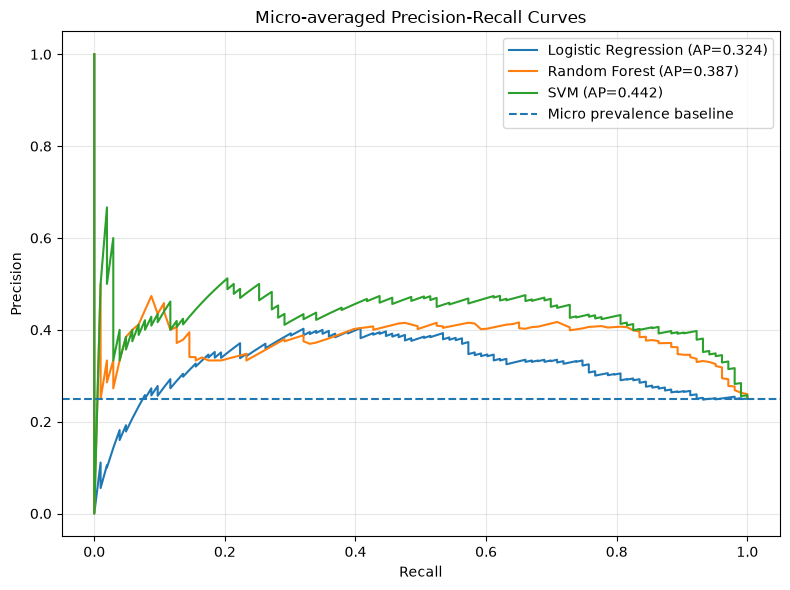

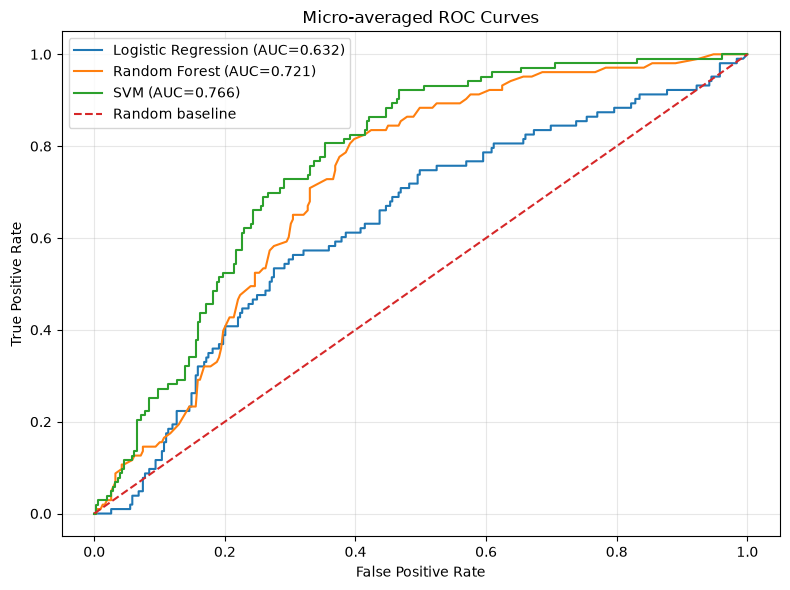


Section 31 completed successfully.
PR/ROC metrics saved in: E:\Asssessment Team\PhD\Data Science\DS_4\results
PR and ROC figures saved in: E:\Asssessment Team\PhD\Data Science\DS_4\figures


In [42]:


# 31. Precision-Recall and ROC evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    average_precision_score,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

# Define project output directories
project_dir = Path(
    r"E:\Asssessment Team\PhD\Data Science\DS_4"
)

results_dir = project_dir / "results"
figures_dir = project_dir / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Ensure previous model results are available
assert all(name in globals() for name in [
    "lr_results", "rf_results", "svm_results"
]), "Run Sections 26, 28, and 29 first."

models = {
    "Logistic Regression": lr_results,
    "Random Forest": rf_results,
    "SVM": svm_results
}

# Convert four classes into one-vs-rest binary targets
class_labels = np.asarray(classes).astype(str)
actual = np.asarray(y).astype(str)

y_binary = label_binarize(
    actual,
    classes=class_labels
)

probability_columns = [
    f"Prob_{label}" for label in classes
]

metric_rows = []
curves = {}

for name, results in models.items():

    # Verify identical observations and frozen folds
    assert np.array_equal(
        results["Actual"].astype(str).to_numpy(),
        actual
    )

    assert np.array_equal(
        results["Fold"].to_numpy(),
        data["Fold"].to_numpy()
    )

    probabilities = (
        results[probability_columns]
        .to_numpy(dtype=float)
    )

    assert np.isfinite(probabilities).all()
    assert np.allclose(
        probabilities.sum(axis=1), 1.0
    )

    # Micro-averaged Precision-Recall curve
    precision, recall, _ = precision_recall_curve(
        y_binary.ravel(),
        probabilities.ravel()
    )

    # Micro-averaged ROC curve
    fpr, tpr, _ = roc_curve(
        y_binary.ravel(),
        probabilities.ravel()
    )

    micro_ap = average_precision_score(
        y_binary.ravel(),
        probabilities.ravel()
    )

    micro_auc = roc_auc_score(
        y_binary.ravel(),
        probabilities.ravel()
    )

    curves[name] = {
        "precision": precision,
        "recall": recall,
        "fpr": fpr,
        "tpr": tpr,
        "ap": micro_ap,
        "auc": micro_auc
    }

    metric_rows.append({
        "Model": name,
        "Class": "Micro average",
        "PR_AP": micro_ap,
        "ROC_AUC": micro_auc
    })

    # Class-specific one-vs-rest metrics
    for j, label in enumerate(class_labels):

        metric_rows.append({
            "Model": name,
            "Class": label,
            "PR_AP": average_precision_score(
                y_binary[:, j],
                probabilities[:, j]
            ),
            "ROC_AUC": roc_auc_score(
                y_binary[:, j],
                probabilities[:, j]
            )
        })

# Save numerical PR/ROC results
pr_roc_results = pd.DataFrame(metric_rows)

print("PR AND ROC PERFORMANCE")
display(pr_roc_results.round(4))

pr_roc_results.to_csv(
    results_dir / "pr_roc_metrics.csv",
    index=False
)

# -----------------------------------------
# Precision-Recall curves
# -----------------------------------------

plt.figure(figsize=(8, 6))

for name, c in curves.items():

    plt.plot(
        c["recall"],
        c["precision"],
        label=f"{name} (AP={c['ap']:.3f})"
    )

plt.axhline(
    y_binary.mean(),
    linestyle="--",
    label="Micro prevalence baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Micro-averaged Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "precision_recall_curves.png",
    dpi=200
)

plt.show()

# -----------------------------------------
# ROC curves
# -----------------------------------------

plt.figure(figsize=(8, 6))

for name, c in curves.items():

    plt.plot(
        c["fpr"],
        c["tpr"],
        label=f"{name} (AUC={c['auc']:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random baseline"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Micro-averaged ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "roc_curves.png",
    dpi=200
)

plt.show()

print("\nSection 31 completed successfully.")
print("PR/ROC metrics saved in:", results_dir)
print("PR and ROC figures saved in:", figures_dir)



PROBABILITY CALIBRATION RESULTS


,Model,Multiclass_Brier,Top_Label_ECE
0,Logistic Regression,0.9939,0.4138
1,Random Forest,0.6756,0.1194
2,SVM,0.6327,0.0139



CALIBRATION BINS


,Model,Bin,Count,Mean_Confidence,Observed_Accuracy
0,Logistic Regression,2,1,0.3420,0.0000
1,Logistic Regression,3,17,0.5107,0.4118
2,Logistic Regression,4,25,0.7124,0.4800
3,Logistic Regression,5,60,0.9298,0.3500
4,Random Forest,2,17,0.3512,0.2353
5,Random Forest,3,77,0.4894,0.3896
6,Random Forest,4,9,0.6267,0.3333
7,SVM,2,33,0.3260,0.3030
8,SVM,3,69,0.4919,0.4928
9,SVM,4,1,0.6160,0.0000


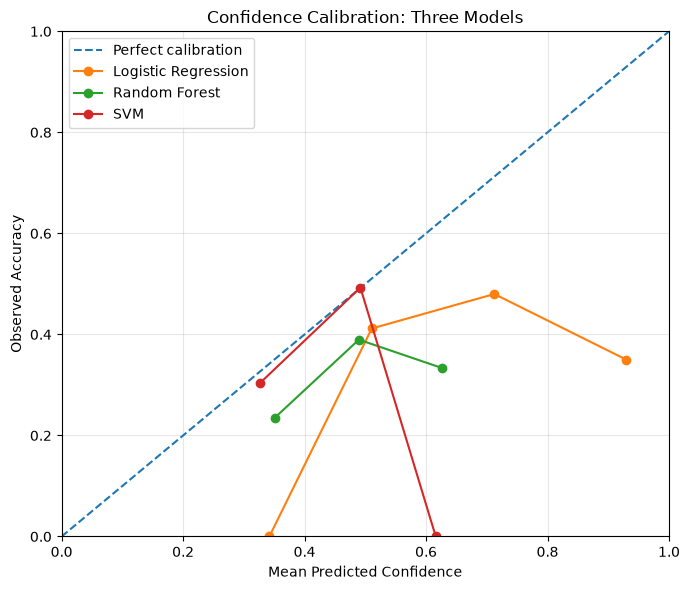


Section 32 completed successfully.
Calibration tables saved in: E:\Asssessment Team\PhD\Data Science\DS_4\results
Calibration figure saved in: E:\Asssessment Team\PhD\Data Science\DS_4\figures


In [43]:


# 32. Probability calibration: Brier Score and ECE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Define project directories
project_dir = Path(
    r"E:\Asssessment Team\PhD\Data Science\DS_4"
)

results_dir = project_dir / "results"
figures_dir = project_dir / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

models = {
    "Logistic Regression": lr_results,
    "Random Forest": rf_results,
    "SVM": svm_results
}

probability_columns = [
    f"Prob_{label}" for label in classes
]

# Fixed calibration protocol: 5 equal-width bins
n_bins = 5
bin_edges = np.linspace(0, 1, n_bins + 1)

calibration_metrics = []
calibration_bins = []

for name, results in models.items():

    assert len(results) == len(y)

    assert np.array_equal(
        results["Actual"].to_numpy(),
        y.to_numpy()
    )

    assert np.array_equal(
        results["Fold"].to_numpy(),
        data["Fold"].to_numpy()
    )

    probabilities = results[
        probability_columns
    ].to_numpy(dtype=float)

    assert np.isfinite(probabilities).all()
    assert np.allclose(
        probabilities.sum(axis=1), 1.0
    )

    # One-hot encoding of actual classes
    y_onehot = (
        y.to_numpy()[:, None] == classes[None, :]
    ).astype(float)

    # Multiclass Brier score
    brier = np.mean(
        np.sum(
            (probabilities - y_onehot) ** 2,
            axis=1
        )
    )

    # Top-label confidence calibration
    confidence = probabilities.max(axis=1)

    predicted = classes[
        probabilities.argmax(axis=1)
    ]

    correct = (
        predicted == y.to_numpy()
    ).astype(float)

    bin_ids = np.digitize(
        confidence,
        bin_edges[1:-1]
    )

    ece = 0.0

    for b in range(n_bins):

        mask = bin_ids == b
        count = int(mask.sum())

        if count == 0:
            continue

        mean_confidence = confidence[mask].mean()
        observed_accuracy = correct[mask].mean()

        ece += (
            count / len(y)
        ) * abs(
            observed_accuracy - mean_confidence
        )

        calibration_bins.append({
            "Model": name,
            "Bin": b + 1,
            "Count": count,
            "Mean_Confidence": mean_confidence,
            "Observed_Accuracy": observed_accuracy
        })

    calibration_metrics.append({
        "Model": name,
        "Multiclass_Brier": brier,
        "Top_Label_ECE": ece
    })

calibration_df = pd.DataFrame(
    calibration_metrics
)

calibration_bins_df = pd.DataFrame(
    calibration_bins
)

print("PROBABILITY CALIBRATION RESULTS")
display(calibration_df.round(4))

print("\nCALIBRATION BINS")
display(calibration_bins_df.round(4))

# Save numerical results in results/
calibration_df.to_csv(
    results_dir / "calibration_metrics.csv",
    index=False
)

calibration_bins_df.to_csv(
    results_dir / "calibration_bins.csv",
    index=False
)

# Plot reliability curves
plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Perfect calibration"
)

for name in models:

    subset = calibration_bins_df[
        calibration_bins_df["Model"] == name
    ]

    plt.plot(
        subset["Mean_Confidence"],
        subset["Observed_Accuracy"],
        marker="o",
        label=name
    )

plt.xlabel("Mean Predicted Confidence")
plt.ylabel("Observed Accuracy")
plt.title("Confidence Calibration: Three Models")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure in figures/
plt.savefig(
    figures_dir / "calibration_curves.png",
    dpi=200
)

plt.show()

print("\nSection 32 completed successfully.")
print("Calibration tables saved in:", results_dir)
print("Calibration figure saved in:", figures_dir)



In [36]:

# 33. Paired bootstrap uncertainty intervals
# 95% percentile intervals using 1000 group-level resamples

import numpy as np
import pandas as pd

from pathlib import Path

rng = np.random.default_rng(42)
n_bootstrap = 1000
n_bins = 5

models = {
    "Logistic Regression": lr_results,
    "Random Forest": rf_results,
    "SVM": svm_results
}

model_names = list(models)
class_labels = np.asarray(classes).astype(str)
actual = y.astype(str).to_numpy()

prob_cols = [f"Prob_{c}" for c in classes]

# Store prediction arrays for each model
model_data = {}

for name, df in models.items():
    assert np.array_equal(
        df["Actual"].astype(str).to_numpy(), actual
    )
    assert np.array_equal(
        df["Fold"].to_numpy(),
        data["Fold"].to_numpy()
    )

    probs = df[prob_cols].to_numpy(dtype=float)

    assert np.isfinite(probs).all()
    assert np.allclose(probs.sum(axis=1), 1.0)

    model_data[name] = {
        "pred": df["Predicted"].astype(str).to_numpy(),
        "prob": probs
    }

# One-hot encode actual classes
y_onehot = (
    actual[:, None] == class_labels[None, :]
).astype(float)

def evaluate_sample(name, idx):
    """Accuracy, multiclass Brier, and top-label ECE."""

    pred = model_data[name]["pred"][idx]
    prob = model_data[name]["prob"][idx]
    true = actual[idx]

    accuracy = np.mean(pred == true)

    brier = np.mean(
        np.sum((prob - y_onehot[idx]) ** 2, axis=1)
    )

    confidence = prob.max(axis=1)
    top_pred = class_labels[prob.argmax(axis=1)]
    correct = (top_pred == true).astype(float)

    bin_ids = np.minimum(
        (confidence * n_bins).astype(int),
        n_bins - 1
    )

    ece = 0.0

    for b in range(n_bins):
        mask = bin_ids == b

        if mask.any():
            ece += mask.mean() * abs(
                correct[mask].mean()
                - confidence[mask].mean()
            )

    return np.array([accuracy, brier, ece])


# Keep related observations together
group_ids = data["Group_ID"].astype(str).to_numpy()
unique_groups = pd.unique(group_ids)

group_indices = [
    np.flatnonzero(group_ids == g)
    for g in unique_groups
]

# Same resampled observations for every model
bootstrap_results = {
    name: np.zeros((n_bootstrap, 3))
    for name in model_names
}

for b in range(n_bootstrap):

    sampled_groups = rng.integers(
        0, len(unique_groups),
        size=len(unique_groups)
    )

    sample_idx = np.concatenate([
        group_indices[g] for g in sampled_groups
    ])

    for name in model_names:
        bootstrap_results[name][b] = evaluate_sample(
            name, sample_idx
        )

# Calculate 95% percentile intervals
metric_names = [
    "Accuracy",
    "Multiclass_Brier",
    "Top_Label_ECE"
]

rows = []
full_idx = np.arange(len(actual))

for name in model_names:

    point_estimates = evaluate_sample(name, full_idx)

    for j, metric in enumerate(metric_names):

        lower, upper = np.percentile(
            bootstrap_results[name][:, j],
            [2.5, 97.5]
        )

        rows.append({
            "Model": name,
            "Metric": metric,
            "Estimate": point_estimates[j],
            "CI_Lower": lower,
            "CI_Upper": upper
        })

intervals_df = pd.DataFrame(rows)

print("95% GROUP-BOOTSTRAP INTERVALS")
display(intervals_df.round(4))

# Paired model differences using identical bootstrap draws
from itertools import combinations

difference_rows = []

for model_a, model_b in combinations(model_names, 2):

    point_a = evaluate_sample(model_a, full_idx)
    point_b = evaluate_sample(model_b, full_idx)

    differences = (
        bootstrap_results[model_a]
        - bootstrap_results[model_b]
    )

    for j, metric in enumerate(metric_names):

        lower, upper = np.percentile(
            differences[:, j],
            [2.5, 97.5]
        )

        difference_rows.append({
            "Comparison": f"{model_a} - {model_b}",
            "Metric": metric,
            "Difference": point_a[j] - point_b[j],
            "CI_Lower": lower,
            "CI_Upper": upper
        })

differences_df = pd.DataFrame(difference_rows)

print("\nPAIRED MODEL DIFFERENCES")
display(differences_df.round(4))

# Save results
results_dir = (
    Path(r"E:\Asssessment Team\PhD\Data Science\DS_4")
    / "results"
)

results_dir.mkdir(parents=True, exist_ok=True)

intervals_df.to_csv(
    results_dir / "bootstrap_intervals.csv",
    index=False
)

differences_df.to_csv(
    results_dir / "paired_bootstrap_differences.csv",
    index=False
)

print("\nUncertainty analysis completed.")
print("Bootstrap repetitions:", n_bootstrap)
print("Resampling unit: Group_ID")
print("Confidence interval: 95% percentile")


95% GROUP-BOOTSTRAP INTERVALS


,Model,Metric,Estimate,CI_Lower,CI_Upper
0,Logistic Regression,Accuracy,0.3883,0.2889,0.4836
1,Logistic Regression,Multiclass_Brier,0.9939,0.8629,1.1228
2,Logistic Regression,Top_Label_ECE,0.4138,0.3295,0.5130
3,Random Forest,Accuracy,0.3592,0.2653,0.4536
4,Random Forest,Multiclass_Brier,0.6756,0.6292,0.7268
5,Random Forest,Top_Label_ECE,0.1194,0.0451,0.2167
6,SVM,Accuracy,0.3883,0.2979,0.4796
7,SVM,Multiclass_Brier,0.6327,0.5967,0.6700
8,SVM,Top_Label_ECE,0.0139,0.0118,0.1217



PAIRED MODEL DIFFERENCES


,Comparison,Metric,Difference,CI_Lower,CI_Upper
0,Logistic Regression - Random Forest,Accuracy,0.0291,-0.0878,0.1416
1,Logistic Regression - Random Forest,Multiclass_Brier,0.3184,0.2093,0.4239
2,Logistic Regression - Random Forest,Top_Label_ECE,0.2945,0.1865,0.4004
3,Logistic Regression - SVM,Accuracy,0.0000,-0.1031,0.1064
4,Logistic Regression - SVM,Multiclass_Brier,0.3612,0.2301,0.4928
5,Logistic Regression - SVM,Top_Label_ECE,0.3999,0.2458,0.4610
6,Random Forest - SVM,Accuracy,-0.0291,-0.1143,0.0637
7,Random Forest - SVM,Multiclass_Brier,0.0428,-0.0052,0.1001
8,Random Forest - SVM,Top_Label_ECE,0.1055,-0.0384,0.1727



Uncertainty analysis completed.
Bootstrap repetitions: 1000
Resampling unit: Group_ID
Confidence interval: 95% percentile


In [37]:

# 34. Critical error slices, failure types, and counterexample

import numpy as np
import pandas as pd

models = {
    "Logistic Regression": lr_results,
    "Random Forest": rf_results,
    "SVM": svm_results
}

actual = y.astype(str).to_numpy()
folds = data["Fold"].to_numpy()
prob_cols = [f"Prob_{c}" for c in classes]

all_cases = []
slice_rows = []

for name, result in models.items():

    # Verify identical evaluation observations
    assert len(result) == len(actual)
    assert np.array_equal(
        result["Actual"].astype(str).to_numpy(),
        actual
    )
    assert np.array_equal(
        result["Fold"].to_numpy(),
        folds
    )

    predictions = result["Predicted"].astype(str).to_numpy()
    probabilities = result[prob_cols].to_numpy(dtype=float)

    assert np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(axis=1), 1.0)

    cases = pd.DataFrame({
        "Model": name,
        "Stratigraphic_unit": data["Stratigraphic_unit"].to_numpy(),
        "Point_ID": data["Point_ID"].to_numpy(),
        "Group_ID": data["Group_ID"].to_numpy(),
        "Fold": folds,
        "Actual": actual,
        "Predicted": predictions,
        "Correct": predictions == actual,
        "Missing_Count": X.isna().sum(axis=1).to_numpy(),
        "Top_Probability": probabilities.max(axis=1),
        "Probability_Top_Class": np.asarray(classes)[
            probabilities.argmax(axis=1)
        ]
    })

    cases["Missingness"] = np.where(
        cases["Missing_Count"] > 0,
        "Has missing values",
        "Complete"
    )

    all_cases.append(cases)

    # Evaluate predefined, interpretable slices
    slice_definitions = {
        "Mineral phase": cases["Actual"],
        "Stratigraphic unit": cases["Stratigraphic_unit"],
        "Missingness": cases["Missingness"]
    }

    for slice_type, values in slice_definitions.items():

        for value in pd.unique(values):

            subset = cases.loc[values == value]

            slice_rows.append({
                "Model": name,
                "Slice_Type": slice_type,
                "Slice": value,
                "N": len(subset),
                "Errors": int((~subset["Correct"]).sum()),
                "Error_Rate": 1 - subset["Correct"].mean()
            })

error_cases_df = pd.concat(
    all_cases, ignore_index=True
)

error_slices_df = pd.DataFrame(slice_rows)

print("ERROR RATES BY MINERAL PHASE")
display(
    error_slices_df[
        error_slices_df["Slice_Type"] == "Mineral phase"
    ].round(4)
)

print("\nERROR RATES BY STRATIGRAPHIC UNIT")
display(
    error_slices_df[
        error_slices_df["Slice_Type"] == "Stratigraphic unit"
    ].round(4)
)

print("\nERROR RATES BY MISSINGNESS")
display(
    error_slices_df[
        error_slices_df["Slice_Type"] == "Missingness"
    ].round(4)
)

# Identify common classification failure types
mistakes = error_cases_df[
    ~error_cases_df["Correct"]
]

failure_types_df = (
    mistakes.groupby(
        ["Model", "Actual", "Predicted"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values(
        ["Model", "Count"],
        ascending=[True, False]
    )
)

print("\nMOST COMMON FAILURE TYPES")
display(
    failure_types_df.groupby("Model").head(5)
)

# Identify an observed counterexample:
# Logistic Regression correct, at least one complex model wrong

prediction_table = pd.DataFrame({
    "Stratigraphic_unit": data["Stratigraphic_unit"],
    "Point_ID": data["Point_ID"],
    "Actual": actual,
    "Logistic_Regression": lr_results["Predicted"].to_numpy(),
    "Random_Forest": rf_results["Predicted"].to_numpy(),
    "SVM": svm_results["Predicted"].to_numpy()
})

counter_mask = (
    (prediction_table["Logistic_Regression"] == actual)
    & (
        (prediction_table["Random_Forest"] != actual)
        | (prediction_table["SVM"] != actual)
    )
)

counterexamples = prediction_table.loc[counter_mask]

print("\nOBSERVED COUNTEREXAMPLE")

if len(counterexamples) > 0:
    display(counterexamples.head(1))
else:
    print(
        "No example found where Logistic Regression "
        "was correct and a complex model was wrong."
    )

# Save evidence for the assignment
error_cases_df.to_csv(
    results_dir / "error_cases.csv",
    index=False
)

error_slices_df.to_csv(
    results_dir / "error_slices.csv",
    index=False
)

failure_types_df.to_csv(
    results_dir / "failure_types.csv",
    index=False
)

counterexamples.to_csv(
    results_dir / "counterexamples.csv",
    index=False
)

print("\nSection 34 completed.")
print("Error-analysis files saved.")


ERROR RATES BY MINERAL PHASE


,Model,Slice_Type,Slice,N,Errors,Error_Rate
0,Logistic Regression,Mineral phase,Oolite core,35,21,0.6000
1,Logistic Regression,Mineral phase,Oolite Rim,27,9,0.3333
2,Logistic Regression,Mineral phase,Pellet Core,20,16,0.8000
3,Logistic Regression,Mineral phase,Pellet Rim,21,17,0.8095
8,Random Forest,Mineral phase,Oolite core,35,20,0.5714
9,Random Forest,Mineral phase,Oolite Rim,27,17,0.6296
10,Random Forest,Mineral phase,Pellet Core,20,14,0.7000
11,Random Forest,Mineral phase,Pellet Rim,21,15,0.7143
16,SVM,Mineral phase,Oolite core,35,11,0.3143
17,SVM,Mineral phase,Oolite Rim,27,17,0.6296



ERROR RATES BY STRATIGRAPHIC UNIT


,Model,Slice_Type,Slice,N,Errors,Error_Rate
4,Logistic Regression,Stratigraphic unit,LPL,21,13,0.6190
5,Logistic Regression,Stratigraphic unit,MPL,33,24,0.7273
6,Logistic Regression,Stratigraphic unit,UPL,49,26,0.5306
12,Random Forest,Stratigraphic unit,LPL,21,14,0.6667
13,Random Forest,Stratigraphic unit,MPL,33,23,0.6970
14,Random Forest,Stratigraphic unit,UPL,49,29,0.5918
20,SVM,Stratigraphic unit,LPL,21,13,0.6190
21,SVM,Stratigraphic unit,MPL,33,23,0.6970
22,SVM,Stratigraphic unit,UPL,49,27,0.5510



ERROR RATES BY MISSINGNESS


,Model,Slice_Type,Slice,N,Errors,Error_Rate
7,Logistic Regression,Missingness,Complete,103,63,0.6117
15,Random Forest,Missingness,Complete,103,66,0.6408
23,SVM,Missingness,Complete,103,63,0.6117



MOST COMMON FAILURE TYPES


,Model,Actual,Predicted,Count
3,Logistic Regression,Oolite core,Oolite Rim,13
11,Logistic Regression,Pellet Rim,Pellet Core,11
8,Logistic Regression,Pellet Core,Pellet Rim,10
0,Logistic Regression,Oolite Rim,Oolite core,6
5,Logistic Regression,Oolite core,Pellet Rim,6
12,Random Forest,Oolite Rim,Oolite core,15
14,Random Forest,Oolite core,Oolite Rim,15
19,Random Forest,Pellet Core,Pellet Rim,9
22,Random Forest,Pellet Rim,Pellet Core,9
21,Random Forest,Pellet Rim,Oolite core,5



OBSERVED COUNTEREXAMPLE


,Stratigraphic_unit,Point_ID,Actual,Logistic_Regression,Random_Forest,SVM
2,LPL,2-3,Oolite core,Oolite core,Oolite Rim,Oolite Rim



Section 34 completed.
Error-analysis files saved.


THRESHOLD DECISION
Model: SVM
Threshold: 0.3346
Review capacity: 20
Observations reviewed: 20
Incorrect automatic predictions: 44
Illustrative total cost: 240.0


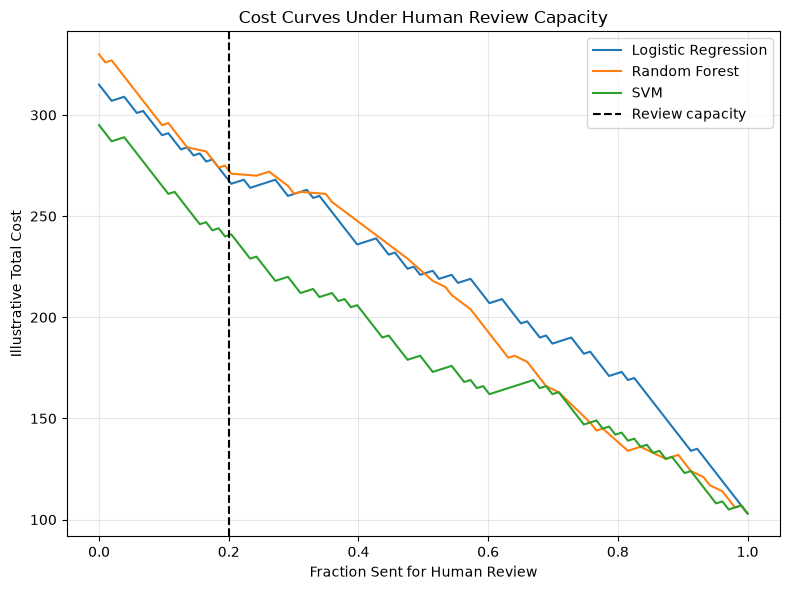


Section 35 completed successfully.
Cost tables saved in: E:\Asssessment Team\PhD\Data Science\DS_4\results
Cost curve saved in: E:\Asssessment Team\PhD\Data Science\DS_4\figures


In [44]:


# 35. Cost-based threshold selection and human review capacity

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Define project directories
project_dir = Path(
    r"E:\Asssessment Team\PhD\Data Science\DS_4"
)

results_dir = project_dir / "results"
figures_dir = project_dir / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Illustrative decision assumptions
review_capacity = 0.20
error_cost = 5.0
review_cost = 1.0

actual = y.astype(str).to_numpy()
class_labels = np.asarray(classes).astype(str)

models = {
    "Logistic Regression": lr_results,
    "Random Forest": rf_results,
    "SVM": svm_results
}

prob_cols = [f"Prob_{c}" for c in classes]

max_reviews = int(
    np.floor(len(actual) * review_capacity)
)

cost_rows = []

for name, results in models.items():

    assert len(results) == len(actual)

    assert np.array_equal(
        results["Actual"].astype(str).to_numpy(),
        actual
    )

    assert np.array_equal(
        results["Fold"].to_numpy(),
        data["Fold"].to_numpy()
    )

    probabilities = results[
        prob_cols
    ].to_numpy(dtype=float)

    assert np.isfinite(probabilities).all()
    assert np.allclose(
        probabilities.sum(axis=1), 1.0
    )

    confidence = probabilities.max(axis=1)

    predictions = class_labels[
        probabilities.argmax(axis=1)
    ]

    thresholds = np.unique(
        np.r_[0.0, np.nextafter(confidence, np.inf)]
    )

    for threshold in thresholds:

        review = confidence < threshold
        automatic = ~review

        n_review = int(review.sum())

        wrong_automatic = int(
            (automatic & (predictions != actual)).sum()
        )

        total_cost = (
            n_review * review_cost
            + wrong_automatic * error_cost
        )

        cost_rows.append({
            "Model": name,
            "Threshold": threshold,
            "Review_Count": n_review,
            "Review_Fraction": n_review / len(actual),
            "Wrong_Automatic": wrong_automatic,
            "Total_Cost": total_cost,
            "Within_Capacity": n_review <= max_reviews
        })

cost_df = pd.DataFrame(cost_rows)

# Select lowest-cost feasible decision
feasible = cost_df[
    cost_df["Within_Capacity"]
].copy()

decision = feasible.sort_values(
    ["Total_Cost", "Review_Count", "Model", "Threshold"]
).iloc[0]

print("THRESHOLD DECISION")
print("Model:", decision["Model"])
print("Threshold:", round(decision["Threshold"], 4))
print("Review capacity:", max_reviews)
print("Observations reviewed:", int(decision["Review_Count"]))
print(
    "Incorrect automatic predictions:",
    int(decision["Wrong_Automatic"])
)
print("Illustrative total cost:", decision["Total_Cost"])

# Save cost results in results/
cost_df.to_csv(
    results_dir / "threshold_cost_curves.csv",
    index=False
)

decision_df = pd.DataFrame([{
    **decision.to_dict(),
    "Assumed_Error_Cost": error_cost,
    "Assumed_Review_Cost": review_cost,
    "Review_Capacity_Fraction": review_capacity,
    "Assumed_Review_Correct": True
}])

decision_df.to_csv(
    results_dir / "threshold_decision_record.csv",
    index=False
)

# Plot cost curves
plt.figure(figsize=(8, 6))

for name in models:

    subset = cost_df[
        cost_df["Model"] == name
    ]

    plt.plot(
        subset["Review_Fraction"],
        subset["Total_Cost"],
        label=name
    )

plt.axvline(
    review_capacity,
    linestyle="--",
    color="black",
    label="Review capacity"
)

plt.xlabel("Fraction Sent for Human Review")
plt.ylabel("Illustrative Total Cost")
plt.title("Cost Curves Under Human Review Capacity")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure in figures/
plt.savefig(
    figures_dir / "threshold_cost_curves.png",
    dpi=200
)

plt.show()

print("\nSection 35 completed successfully.")
print("Cost tables saved in:", results_dir)
print("Cost curve saved in:", figures_dir)


In [39]:

# 36. Sensitivity analysis of cost and review capacity

import numpy as np
import pandas as pd

# Baseline and four alternative scenarios
# Values are illustrative, not real operational costs

scenarios = [
    ("Baseline", 0.20, 5),
    ("Lower capacity", 0.10, 5),
    ("Higher capacity", 0.30, 5),
    ("Lower error cost", 0.20, 3),
    ("Higher error cost", 0.20, 10)
]

review_cost = 1.0
sensitivity_rows = []

for scenario, capacity, error_cost in scenarios:

    max_reviews = int(np.floor(len(y) * capacity))

    # Use existing predictions and threshold results
    feasible = cost_df[
        cost_df["Review_Count"] <= max_reviews
    ].copy()

    feasible["Scenario_Cost"] = (
        feasible["Review_Count"] * review_cost
        + feasible["Wrong_Automatic"] * error_cost
    )

    # Select lowest-cost feasible decision
    best = feasible.sort_values(
        ["Scenario_Cost", "Review_Count", "Model", "Threshold"]
    ).iloc[0]

    sensitivity_rows.append({
        "Scenario": scenario,
        "Review_Capacity": capacity,
        "Error_Cost": error_cost,
        "Selected_Model": best["Model"],
        "Threshold": best["Threshold"],
        "Reviews": int(best["Review_Count"]),
        "Wrong_Automatic": int(best["Wrong_Automatic"]),
        "Total_Cost": best["Scenario_Cost"]
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)

print("THRESHOLD SENSITIVITY ANALYSIS")

display(sensitivity_df.round(4))

# Save required sensitivity evidence
sensitivity_df.to_csv(
    results_dir / "threshold_sensitivity.csv",
    index=False
)

print("\nSensitivity analysis saved successfully.")


THRESHOLD SENSITIVITY ANALYSIS


,Scenario,Review_Capacity,Error_Cost,Selected_Model,Threshold,Reviews,Wrong_Automatic,Total_Cost
0,Baseline,0.2,5,SVM,0.3346,20,44,240.0
1,Lower capacity,0.1,5,SVM,0.3013,10,51,265.0
2,Higher capacity,0.3,5,SVM,0.3614,28,38,218.0
3,Lower error cost,0.2,3,SVM,0.3346,20,44,152.0
4,Higher error cost,0.2,10,SVM,0.3346,20,44,460.0



Sensitivity analysis saved successfully.


In [45]:


# 37. Verify required DS-A4 output files

from pathlib import Path
import pandas as pd

project_dir = Path(
    r"E:\Asssessment Team\PhD\Data Science\DS_4"
)

results_dir = project_dir / "results"
figures_dir = project_dir / "figures"

required_results = [
    "frozen_fold_assignments.csv",
    "logistic_regression_oof_predictions.csv",
    "svm_oof_predictions.csv",
    "paired_model_predictions.csv",
    "model_comparison.csv",
    "paired_fold_accuracy.csv",
    "pr_roc_metrics.csv",
    "calibration_metrics.csv",
    "calibration_bins.csv",
    "bootstrap_intervals.csv",
    "paired_bootstrap_differences.csv",
    "error_cases.csv",
    "error_slices.csv",
    "failure_types.csv",
    "counterexamples.csv",
    "threshold_cost_curves.csv",
    "threshold_decision_record.csv",
    "threshold_sensitivity.csv"
]

required_figures = [
    "precision_recall_curves.png",
    "roc_curves.png",
    "calibration_curves.png",
    "threshold_cost_curves.png"
]

def check_files(folder, filenames):

    return pd.DataFrame({
        "File": filenames,
        "Exists": [
            (folder / name).is_file()
            for name in filenames
        ]
    })

results_check = check_files(
    results_dir, required_results
)

figures_check = check_files(
    figures_dir, required_figures
)

print("RESULTS FOLDER")
display(results_check)

print("\nFIGURES FOLDER")
display(figures_check)

print("\nSUMMARY")

print(
    "Results:",
    results_check["Exists"].sum(),
    "/",
    len(required_results)
)

print(
    "Figures:",
    figures_check["Exists"].sum(),
    "/",
    len(required_figures)
)

if (
    results_check["Exists"].all()
    and figures_check["Exists"].all()
):
    print("\nAll checked output files are present.")
else:
    print("\nSome required files are missing.")



RESULTS FOLDER


,File,Exists
0,frozen_fold_assignments.csv,True
1,logistic_regression_oof_predictions.csv,True
2,svm_oof_predictions.csv,True
3,paired_model_predictions.csv,True
4,model_comparison.csv,True
5,paired_fold_accuracy.csv,True
6,pr_roc_metrics.csv,True
7,calibration_metrics.csv,True
8,calibration_bins.csv,True
9,bootstrap_intervals.csv,True



FIGURES FOLDER


,File,Exists
0,precision_recall_curves.png,True
1,roc_curves.png,True
2,calibration_curves.png,True
3,threshold_cost_curves.png,True



SUMMARY
Results: 18 / 18
Figures: 4 / 4

All checked output files are present.
